## Airbnb Data Inspection

### Import the essential libraries

In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

###load the data

In [128]:
df_l = pd.read_csv('/content/Listings.csv', encoding='latin-1', on_bad_lines='skip', engine='python')

### Inspect the first 10 rows

In [129]:
df_l.head(10)

,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
0,281420,"Beautiful Flat in le Village Montmartre, Paris",1466919,2011-12-03,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
1,3705183,39 mÃÂ² Paris (Sacre CÃ âur),10328771,2013-11-29,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
2,4082273,"Lovely apartment with Terrace, 60m2",19252768,2014-07-31,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
3,4797344,Cosy studio (close to Eiffel tower),10668311,2013-12-17,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
4,4823489,Close to Eiffel Tower - Beautiful flat : 2 rooms,24837558,2014-12-14,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
5,4898654,NEW - Charming apartment Le Marais,505535,2011-04-13,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
6,6021700,2P - Entre Bastille et Republique,8053690,2013-08-09,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
7,6945740,57sqm btw. Bastille & PÃÂ¨re Lachaise,5924709,2013-04-14,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
8,7491966,Charming appartment near the Parc Buttes Chaumont,35812762,2015-06-14,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
9,7849932,Bel appartement plein de charme !,20833291,2014-09-02,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f


### Number of rows and columns

In [130]:
df_l.shape

(279712, 33)

In [131]:
print(f"Number of columns: {len(df_l.columns)}")
df_l.columns

Number of columns: 33


Index(['listing_id', 'name', 'host_id', 'host_since', 'host_location',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_total_listings_count',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourhood',
       'district', 'city', 'latitude', 'longitude', 'property_type',
       'room_type', 'accommodates', 'bedrooms', 'amenities', 'price',
       'minimum_nights', 'maximum_nights', 'review_scores_rating',
       'review_scores_accuracy', 'review_scores_cleanliness',
       'review_scores_checkin', 'review_scores_communication',
       'review_scores_location', 'review_scores_value', 'instant_bookable'],
      dtype='object')

### Explanation of Dataset Columns in Simple Terms

#### 🔑 Identifiers & Basic Info
* **`listing_id`**: The unique ID number for the Airbnb listing.
* **`name`**: The title/description of the listing as seen by guests.
* **`host_id`**: The unique ID number of the person who hosts the listing.

#### 👤 Host Information
* **`host_since`**: The date when the host first joined Airbnb.
* **`host_location`**: Where the host is located (city/country).
* **`host_response_time`**: How quickly the host typically replies to messages (e.g., 'within an hour').
* **`host_response_rate`**: The percentage of guest messages the host responds to.
* **`host_acceptance_rate`**: The percentage of booking requests the host accepts.
* **`host_is_superhost`**: Whether the host has earned 'Superhost' status (True/False).
* **`host_total_listings_count`**: The total number of properties this host has listed on Airbnb.
* **`host_has_profile_pic`**: Whether the host has a profile picture uploaded.
* **`host_identity_verified`**: Whether the host's identity has been verified by Airbnb.

#### 📍 Location Details
* **`neighbourhood`**: The specific neighborhood where the listing is located.
* **`district`**: The administrative district (if applicable, e.g., in Paris).
* **`city`**: The city where the listing is located.
* **`latitude` / `longitude`**: The geographic coordinates of the property.

#### 🏠 Property & Accommodations
* **`property_type`**: The type of building (e.g., Apartment, House, Loft).
* **`room_type`**: The space setup (e.g., Entire home/apt, Private room, Shared room).
* **`accommodates`**: The maximum number of guests allowed.
* **`bedrooms`**: The number of bedrooms in the property.
* **`amenities`**: A list of features and items provided (e.g., Wi-Fi, kitchen, heating).

#### 📅 Pricing & Booking Rules
* **`price`**: The price per night to stay at the property.
* **`minimum_nights`**: The shortest stay allowed by the host.
* **`maximum_nights`**: The longest stay allowed by the host.
* **`instant_bookable`**: Whether guests can book immediately without waiting for host approval.

#### ⭐ Review Scores (Ratings out of 10 or 100)
* **`review_scores_rating`**: The overall rating score given by guests (usually out of 100).
* **`review_scores_accuracy`**: How accurately the listing description matched the actual place.
* **`review_scores_cleanliness`**: How clean the property was.
* **`review_scores_checkin`**: How smooth the check-in process was.
* **`review_scores_communication`**: How well the host communicated with the guest.
* **`review_scores_location`**: How highly guests rated the location of the property.
* **`review_scores_value`**: Whether guests felt the stay was worth the money spent.

##Check Data Types

In [132]:
df_l.dtypes

,0
listing_id,int64
name,object
host_id,int64
host_since,object
host_location,object
host_response_time,object
host_response_rate,float64
host_acceptance_rate,float64
host_is_superhost,object
host_total_listings_count,float64


In [133]:
df_l.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279712 entries, 0 to 279711
Data columns (total 33 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   listing_id                   279712 non-null  int64  
 1   name                         279537 non-null  object 
 2   host_id                      279712 non-null  int64  
 3   host_since                   279547 non-null  object 
 4   host_location                278872 non-null  object 
 5   host_response_time           150930 non-null  object 
 6   host_response_rate           150930 non-null  float64
 7   host_acceptance_rate         166625 non-null  float64
 8   host_is_superhost            279547 non-null  object 
 9   host_total_listings_count    279547 non-null  float64
 10  host_has_profile_pic         279547 non-null  object 
 11  host_identity_verified       279547 non-null  object 
 12  neighbourhood                279712 non-null  object 
 13 

### Descriptive Statistics of the Data

In [134]:
df_l.describe()

,listing_id,host_id,host_response_rate,host_acceptance_rate,host_total_listings_count,latitude,longitude,accommodates,bedrooms,price,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value
count,2.797120e+05,2.797120e+05,150930.000000,166625.000000,279547.000000,279712.000000,279712.000000,279712.000000,250277.000000,279712.000000,279712.000000,2.797120e+05,188307.000000,187999.000000,188047.000000,187941.000000,188025.000000,187937.000000,187927.000000
mean,2.638196e+07,1.081658e+08,0.865939,0.827168,24.581612,18.761862,12.595075,3.288736,1.515509,608.792737,8.050967,2.755860e+04,93.405195,9.565476,9.312869,9.701534,9.698593,9.633994,9.335364
std,1.442576e+07,1.108570e+08,0.283744,0.289202,284.041143,32.560343,73.081309,2.133379,1.153080,3441.826611,31.518946,7.282875e+06,10.070437,0.990878,1.146072,0.867434,0.886884,0.833234,1.042625
min,2.577000e+03,1.822000e+03,0.000000,0.000000,0.000000,-34.264400,-99.339630,0.000000,1.000000,0.000000,1.000000,1.000000e+00,20.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,1.384462e+07,1.720656e+07,0.900000,0.780000,1.000000,-22.964390,-43.198040,2.000000,1.000000,75.000000,1.000000,4.500000e+01,91.000000,9.000000,9.000000,10.000000,10.000000,9.000000,9.000000
50%,2.767098e+07,5.826911e+07,1.000000,0.980000,1.000000,40.710785,2.382780,2.000000,1.000000,150.000000,2.000000,1.125000e+03,96.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
75%,3.978485e+07,1.832853e+08,1.000000,1.000000,4.000000,41.908610,28.986730,4.000000,2.000000,474.000000,5.000000,1.125000e+03,100.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
max,4.834353e+07,3.901874e+08,1.000000,1.000000,7235.000000,48.904910,151.339810,16.000000,50.000000,625216.000000,9999.000000,2.147484e+09,100.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


In [135]:
df_l.describe(include='object')

,name,host_since,host_location,host_response_time,host_is_superhost,host_has_profile_pic,host_identity_verified,neighbourhood,district,city,property_type,room_type,amenities,instant_bookable
count,279537,279547,278872,150930,279547,279547,279547,279712,37012,279712,279712,279712,279712,279712
unique,265860,4240,7159,4,2,2,2,660,5,10,144,4,245003,2
top,home away from home,2019-09-02,"Paris, Ile-de-France, France",within an hour,f,t,t,I Centro Storico,Manhattan,Paris,Entire apartment,Entire place,"[""Long term stays allowed""]",f
freq,98,710,47794,83464,229294,278631,201191,14874,16553,64690,138989,182005,1388,164105


##Check for Missing Values

In [136]:
df_l.isnull().sum()

,0
listing_id,0
name,175
host_id,0
host_since,165
host_location,840
host_response_time,128782
host_response_rate,128782
host_acceptance_rate,113087
host_is_superhost,165
host_total_listings_count,165


## Check for Duplicates

In [137]:
print(f"Duplicate rows: {df_l.duplicated().sum()}")

Duplicate rows: 0


In [138]:
df_l.nunique()

,0
listing_id,279712
name,265860
host_id,182024
host_since,4240
host_location,7159
host_response_time,4
host_response_rate,91
host_acceptance_rate,101
host_is_superhost,2
host_total_listings_count,206


In [139]:
# check data whose name is absent
df_l[df_l['name'].isnull()]

,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
388,4661616,NaN,24121498,2014-11-24,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,3,1125,90.0,10.0,10.0,10.0,10.0,10.0,10.0,f
1260,11811541,NaN,62910102,2016-03-14,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,3,1125,100.0,10.0,10.0,10.0,10.0,9.0,10.0,f
1441,12355699,NaN,66731989,2016-04-11,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,93.0,9.0,9.0,10.0,10.0,10.0,10.0,f
2047,6076734,NaN,31542193,2015-04-19,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,4,1125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f
2439,9102328,NaN,37083488,2015-06-29,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
277870,13841478,NaN,3956613,2012-10-23,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,5,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,t
278005,7200274,NaN,1573888,2012-01-06,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,1,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f
278043,13320569,NaN,18582780,2014-07-21,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f
278715,13932312,NaN,28413985,2015-02-26,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,20,96.0,10.0,10.0,10.0,10.0,9.0,10.0,f


In [140]:
# replace null names with 'Not Provided'
df_l['name'] = df_l['name'].fillna('Not Provided')
print(f"Remaining null names: {df_l['name'].isnull().sum()}")

Remaining null names: 0


In [141]:
df_l.isnull().sum()

,0
listing_id,0
name,0
host_id,0
host_since,165
host_location,840
host_response_time,128782
host_response_rate,128782
host_acceptance_rate,113087
host_is_superhost,165
host_total_listings_count,165


In [142]:
# check data wherer host response time is null
df_l[df_l['host_response_time'].isnull()]

,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
0,281420,"Beautiful Flat in le Village Montmartre, Paris",1466919,2011-12-03,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
1,3705183,39 mÃÂ² Paris (Sacre CÃ âur),10328771,2013-11-29,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
2,4082273,"Lovely apartment with Terrace, 60m2",19252768,2014-07-31,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
3,4797344,Cosy studio (close to Eiffel tower),10668311,2013-12-17,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
4,4823489,Close to Eiffel Tower - Beautiful flat : 2 rooms,24837558,2014-12-14,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
279707,38338635,Appartement T2 neuf prÃÂ¨s du tram T3a Porte ...,31161181,2015-04-13,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,1,7,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
279708,38538692,Cozy Studio in Montmartre,10294858,2013-11-27,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,7,15,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
279709,38683356,Nice and cosy mini-appartement in Paris,2238502,2012-04-27,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,6,30,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
279710,39659000,Charming apartment near Rue Saint Maur / Oberk...,38633695,2015-07-16,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,3,18,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f


In [143]:
df_l['host_response_time'].value_counts()

,count
host_response_time,
within an hour,83464
within a few hours,28891
within a day,23425
a few days or more,15150


In [144]:
# replace host_response_time with nulls with 'Unknown'
df_l['host_response_time'] = df_l['host_response_time'].fillna('Unknown')
print(f"Remaining null host_response_time: {df_l['host_response_time'].isnull().sum()}")

Remaining null host_response_time: 0


In [145]:
cat_with_nulls= ['host_has_profile_pic', 'host_identity_verified', 'host_is_superhost', 'host_location', 'district']

# create a loop that convert missing values in each of the cat_with_nulls cols into 'Unknown'
for col in cat_with_nulls:
  df_l[col] = df_l[col].fillna('Unknown')
  print(f"Remaining null {col}: {df_l[col].isnull().sum()}")

Remaining null host_has_profile_pic: 0
Remaining null host_identity_verified: 0
Remaining null host_is_superhost: 0
Remaining null host_location: 0
Remaining null district: 0


In [146]:
df_l.isnull().sum()

,0
listing_id,0
name,0
host_id,0
host_since,165
host_location,0
host_response_time,0
host_response_rate,128782
host_acceptance_rate,113087
host_is_superhost,0
host_total_listings_count,165


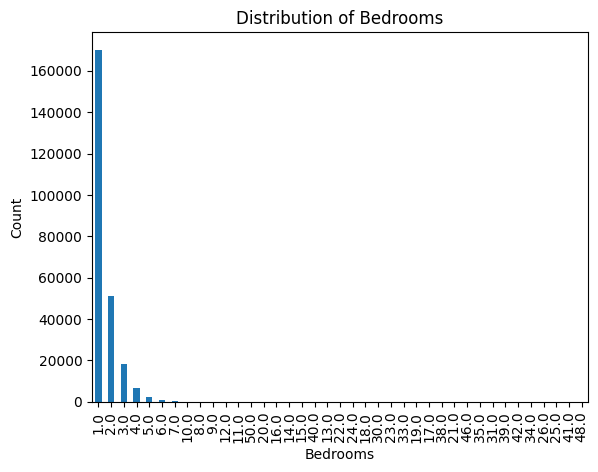

In [147]:
# check the disturbution of the bedrooms before imputation (a visual)
df_l['bedrooms'].value_counts().plot(kind='bar')
plt.title('Distribution of Bedrooms')
plt.xlabel('Bedrooms')
plt.ylabel('Count')
plt.show()

In [148]:
# replace the null values of the bedrooms with the value of the bedrooms that share similar room_type , property_type and accomdates (group_based mode)
df_l['bedrooms'] = df_l.groupby(['room_type', 'property_type', 'accommodates'])['bedrooms'].transform(lambda x: x.fillna(x.mode()))
df_l['bedrooms'] = df_l['bedrooms'].fillna(0)
print(f"Remaining null bedrooms: {df_l['bedrooms'].isnull().sum()}")

Remaining null bedrooms: 0


In [149]:
df_l['bedrooms'].dtype

dtype('float64')

In [150]:
df_l['bedrooms'].value_counts()

,count
bedrooms,
1.0,170163
2.0,51382
0.0,29435
3.0,18525
4.0,6579
5.0,2106
6.0,701
7.0,246
10.0,150


In [151]:
# check how many imputed bedroom values ended with not_integer bedroom values
df_l[df_l['bedrooms'] % 1 != 0]['bedrooms'].value_counts()


,count
bedrooms,


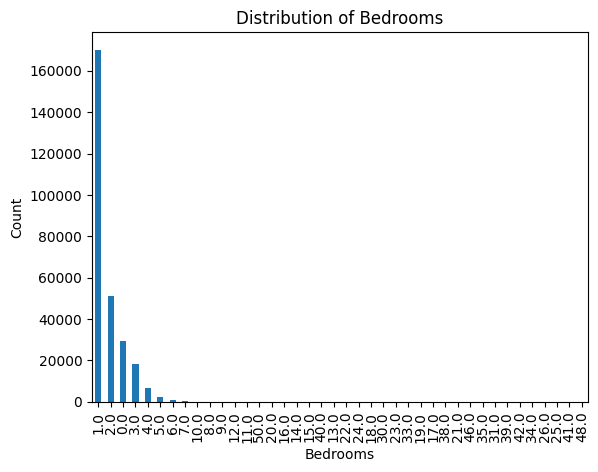

In [152]:
# check disturbution after imputation
df_l['bedrooms'].value_counts().plot(kind='bar')
plt.title('Distribution of Bedrooms')
plt.xlabel('Bedrooms')
plt.ylabel('Count')
plt.show()

In [153]:
# has total listing is null
df_l[df_l['host_total_listings_count'].isnull()]

,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
52879,5872399,Deux piÃÂ¨ces cosy au coeur du 11ÃÂ¨me,1721954,NaN,Unknown,Unknown,NaN,NaN,Unknown,NaN,...,1,1125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f
52880,6300239,Deux piÃÂ¨ces cosy au coeur du 11ieme,1721954,NaN,Unknown,Unknown,NaN,NaN,Unknown,NaN,...,1,1125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f
52881,6875069,75 m2 Apartment Monceau,20618245,NaN,Unknown,Unknown,NaN,NaN,Unknown,NaN,...,3,1125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f
52882,7070896,A couple/ family - you'll love it!,37073350,NaN,Unknown,Unknown,NaN,NaN,Unknown,NaN,...,4,1125,97.0,10.0,10.0,10.0,10.0,9.0,10.0,t
52883,7526817,Studio next to Ile Saint Louis,33200781,NaN,Unknown,Unknown,NaN,NaN,Unknown,NaN,...,3,1125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
229887,36097566,Penelope's House,271523825,NaN,Unknown,Unknown,NaN,NaN,Unknown,NaN,...,2,30,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
229888,36159429,Vatican St Peter Apartment Daniele,271964652,NaN,Unknown,Unknown,NaN,NaN,Unknown,NaN,...,2,29,98.0,10.0,10.0,10.0,10.0,10.0,10.0,t
229889,36173459,Vatican St.Peter's Daniel,272057403,NaN,Unknown,Unknown,NaN,NaN,Unknown,NaN,...,2,29,98.0,10.0,10.0,10.0,10.0,10.0,10.0,t
229890,36251422,Apartment Vatican Cardinale,272661142,NaN,Unknown,Unknown,NaN,NaN,Unknown,NaN,...,2,29,97.0,10.0,10.0,10.0,10.0,10.0,10.0,f


In [154]:
# total listings count is 0
list_count_zero = df_l[df_l['host_total_listings_count'] == 0]


In [155]:
# now chech the number of listings id for each host within this dataset
list_count_zero.groupby('host_id')['listing_id'].count().sort_values(ascending=False)

,listing_id
host_id,
291007369,627
371026651,295
279001183,189
353326613,151
371972456,65
...,...
62209312,1
62192916,1
62133767,1


In [156]:
df_l[df_l['host_total_listings_count'] == 0]

,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
36449,47355968,Charmant appartement parisien - 2/4 voyageurs,11716309,2014-01-28,"Paris, Ile-de-France, France",within a few hours,0.88,0.33,f,0.0,...,5,1125,100.0,10.0,10.0,10.0,8.0,8.0,8.0,f
36458,39029972,"New high-end furniture, Center of the World",273344288,2019-07-03,"Hallandale Beach, Florida, United States",within a day,0.75,0.25,f,0.0,...,30,1125,20.0,6.0,8.0,6.0,8.0,8.0,4.0,f
36499,11313271,"Beautiful, Spacious Studio/1 BR in Gramercy",41821010,2015-08-18,"New York, New York, United States",within an hour,0.67,0.84,f,0.0,...,30,1125,91.0,9.0,9.0,9.0,9.0,9.0,9.0,t
36510,35711402,Amazing Brooklyn 1Bd with Private Balcony,12061757,2014-02-08,"New York, New York, United States",a few days or more,0.00,0.00,f,0.0,...,30,1125,87.0,9.0,9.0,10.0,9.0,9.0,9.0,f
36512,36172164,Sleeping Easy on the East Side! 1 Bed/1 Bath,270629822,2019-06-22,"New York, New York, United States",a few days or more,0.00,1.00,f,0.0,...,30,1125,94.0,9.0,9.0,9.0,9.0,9.0,9.0,f
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
250139,33128709,IMPERIAL VATICAN HOME - near Saint Peter Church,249398566,2019-03-17,"Rome, Lazio, Italy",within an hour,1.00,1.00,t,0.0,...,2,30,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
250140,33574716,SUITE VATICAN HOME,249398566,2019-03-17,"Rome, Lazio, Italy",within an hour,1.00,1.00,t,0.0,...,2,30,96.0,10.0,10.0,10.0,10.0,10.0,10.0,f
250142,39073630,Ã°Å¸âÂ»PerfectPlaceToWorkInFocusÃ¢Ëâ¬Ã¯Â¸Â...,299024632,2019-09-30,"Rome, Lazio, Italy",within an hour,1.00,1.00,t,0.0,...,2,60,98.0,10.0,10.0,10.0,10.0,10.0,10.0,f
250143,40935774,St Peter R(h)ome *NEW*,37466391,2015-07-04,"Rome, Lazio, Italy",within an hour,1.00,1.00,t,0.0,...,1,15,98.0,10.0,10.0,10.0,10.0,10.0,10.0,f


In [157]:
# create a new col called host_listings_counts_in_datasets (group by host and get the count of the listings per host)
df_l['host_listings_counts_in_datasets'] = df_l.groupby('host_id')['listing_id'].transform('count')


In [158]:
df_l['host_listings_counts_in_datasets'].value_counts().sort_values(ascending=False)

,count
host_listings_counts_in_datasets,
1,150165
2,34718
3,16989
4,11192
5,8360
...,...
66,66
65,65
60,60


## Check the Data again for any nulls that need to be handled

In [159]:
df_l.isnull().sum()

,0
listing_id,0
name,0
host_id,0
host_since,165
host_location,0
host_response_time,0
host_response_rate,128782
host_acceptance_rate,113087
host_is_superhost,0
host_total_listings_count,165


In [160]:
df_l.shape

(279712, 34)

## Chech the Disturbution of Price

In [161]:
df_l['price'].value_counts()

,count
price,
100,6882
50,6438
70,6207
60,6172
80,6148
...,...
2904,1
3094,1
7273,1


### Detailed Price Distribution Analysis
Since the overall price boxplot is heavily skewed by massive outliers (with prices up to 625,216), let's look at the summary statistics and plot a distribution of the majority of listings (e.g., properties priced under $1,000) to see the detail.

count    279712.000000
mean        608.792737
std        3441.826611
min           0.000000
25%          75.000000
50%         150.000000
75%         474.000000
max      625216.000000
Name: price, dtype: float64


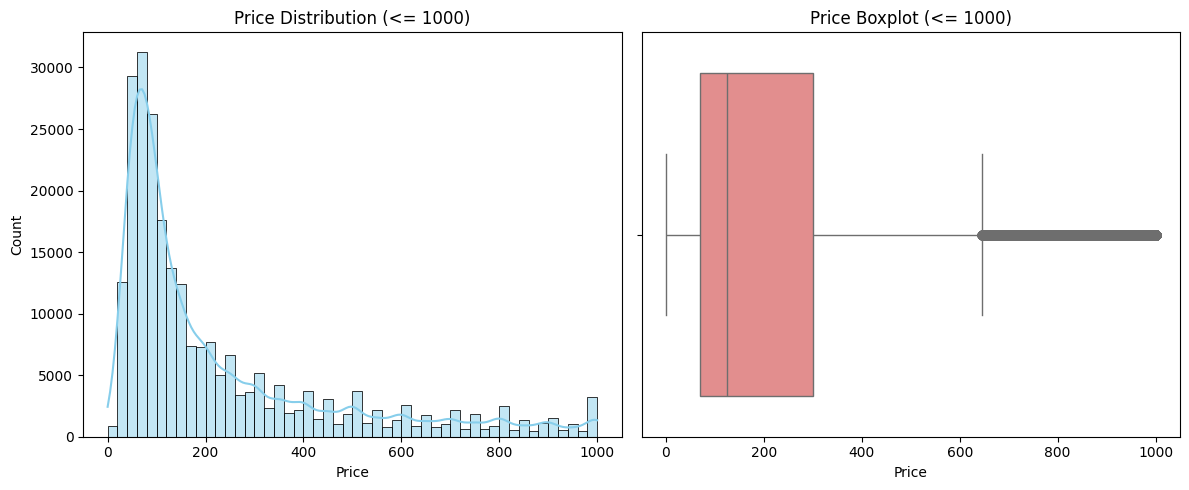

In [162]:
# Print summary statistics for price
print(df_l['price'].describe())

# Plotting distribution for listings priced under 1000 to see the typical price distribution
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_l[df_l['price'] <= 1000]['price'], bins=50, kde=True, color='skyblue')
plt.title('Price Distribution (<= 1000)')
plt.xlabel('Price')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.boxplot(x=df_l[df_l['price'] <= 1000]['price'], color='lightcoral')
plt.title('Price Boxplot (<= 1000)')
plt.xlabel('Price')

plt.tight_layout()
plt.show()

In [163]:
# check data with zero or negative prices
df_l[df_l['price'] <= 0]


,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,host_listings_counts_in_datasets
98209,44312919,Bienvenue ÃÂ l'HÃÂ´tel des 3 CollÃÂ¨ges,357400186,2020-07-20,FR,Unknown,NaN,NaN,f,0.0,...,1125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,1
202022,42830099,Hotel Hugo,300800542,2019-10-07,"New York, New York, United States",within an hour,1.0,1.00,f,9.0,...,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,1
202023,43247472,Hotel 57,324955773,2020-01-06,"New York, New York, United States",within an hour,1.0,1.00,f,4.0,...,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,1
203253,43205598,Wellington Hotel,335389657,2020-02-11,"New York, New York, United States",within an hour,1.0,1.00,f,0.0,...,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,1
203254,44567521,"The Standard, East Village",360662584,2020-08-05,US,within an hour,1.0,1.00,f,0.0,...,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208940,42534857,A.Roma Lifestyle Hotel,309508008,2019-11-14,IT,Unknown,NaN,NaN,f,0.0,...,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,1
208941,43036135,Hotel Principessa Isabella,312575420,2019-11-27,"Cape Town, Western Cape, South Africa",Unknown,NaN,NaN,f,0.0,...,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,1
210617,42065564,The Wall Street Inn,314151200,2019-12-03,"New York, New York, United States",within a day,0.8,0.86,f,8.0,...,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,9
212834,43308777,Peace & Love Hostel,333135832,2020-02-03,FR,within a day,1.0,0.99,f,1.0,...,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,f,6


In [164]:
# drop rows with price = 0
df_l.drop(df_l[df_l['price'] <= 0].index, inplace=True)

In [165]:
df_l['city'].value_counts()

,count
city,
Paris,64628
New York,36984
Sydney,33630
Rome,27641
Rio de Janeiro,26608
Istanbul,24517
Mexico City,20058
Bangkok,19360
Cape Town,19086


Summary statistics for Paris:


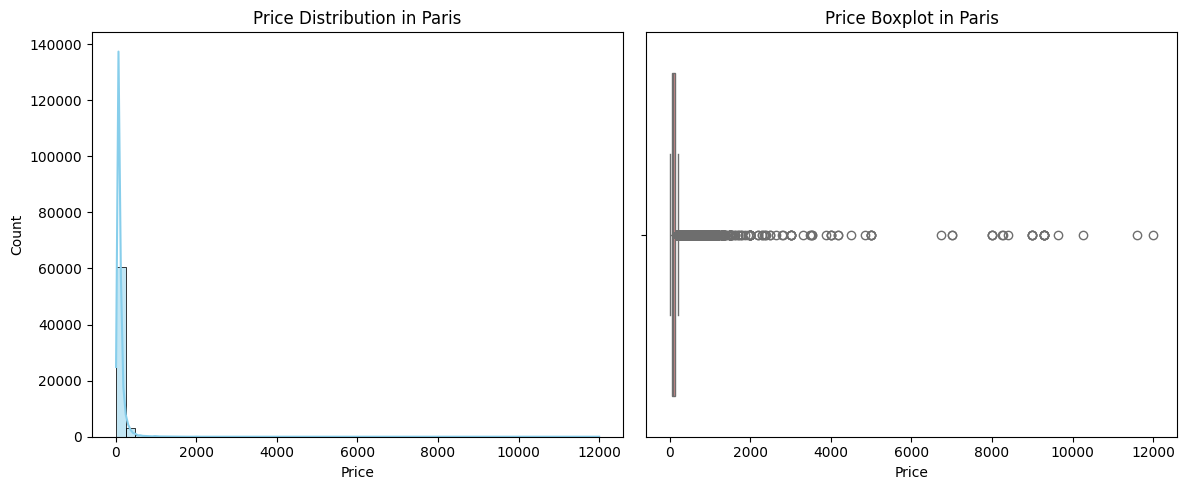



Summary statistics for New York:


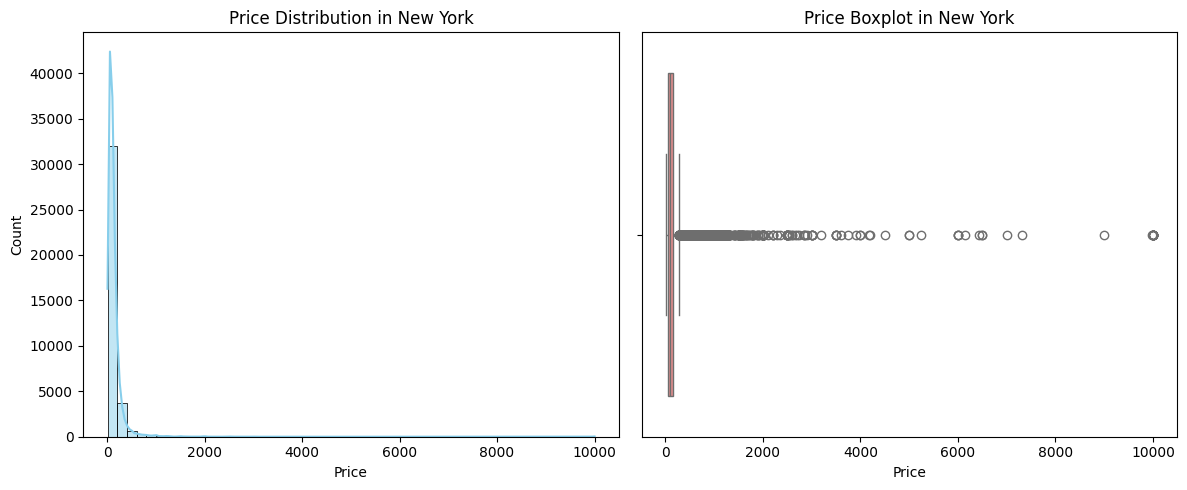



Summary statistics for Bangkok:


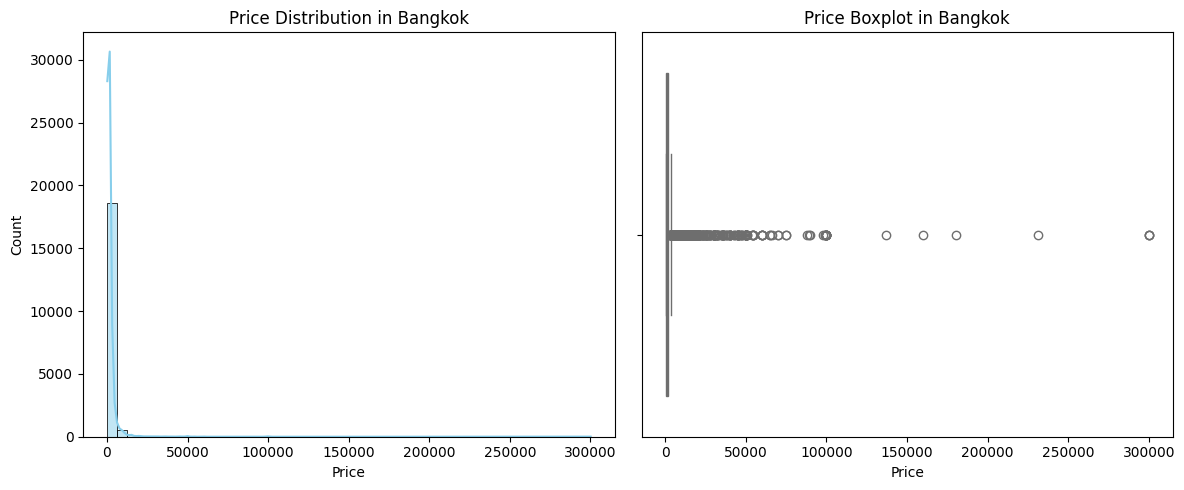



Summary statistics for Rio de Janeiro:


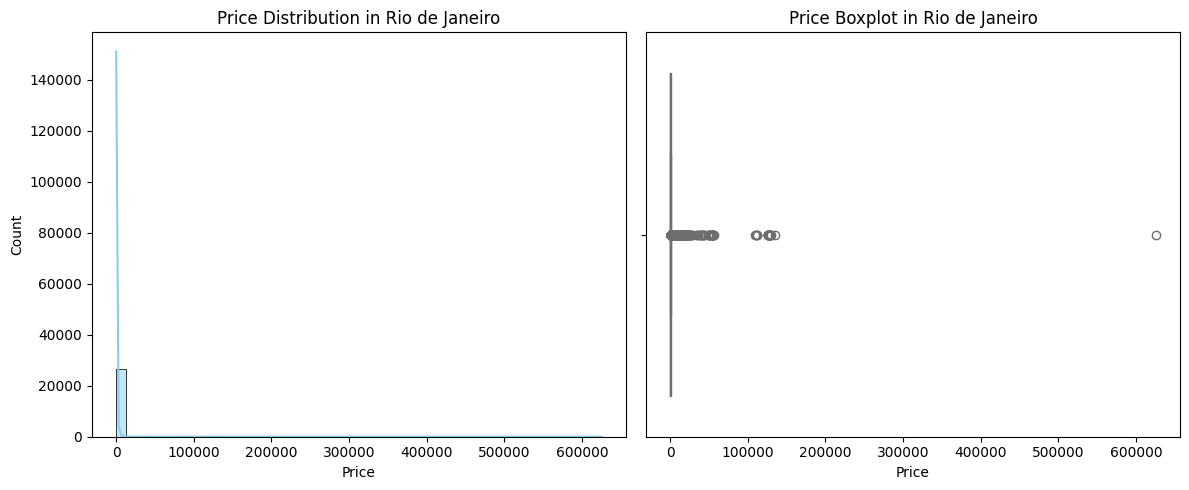



Summary statistics for Sydney:


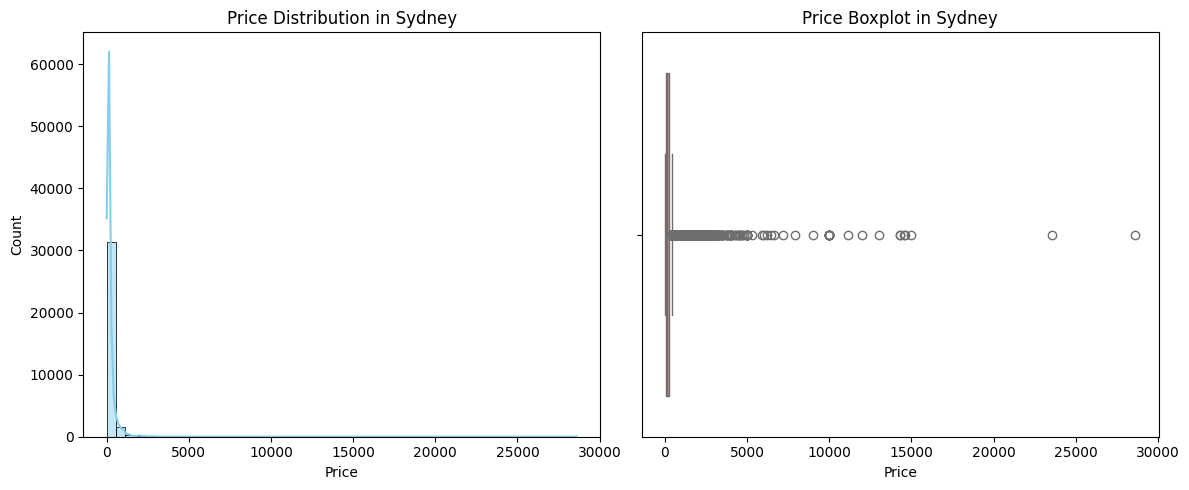



Summary statistics for Istanbul:


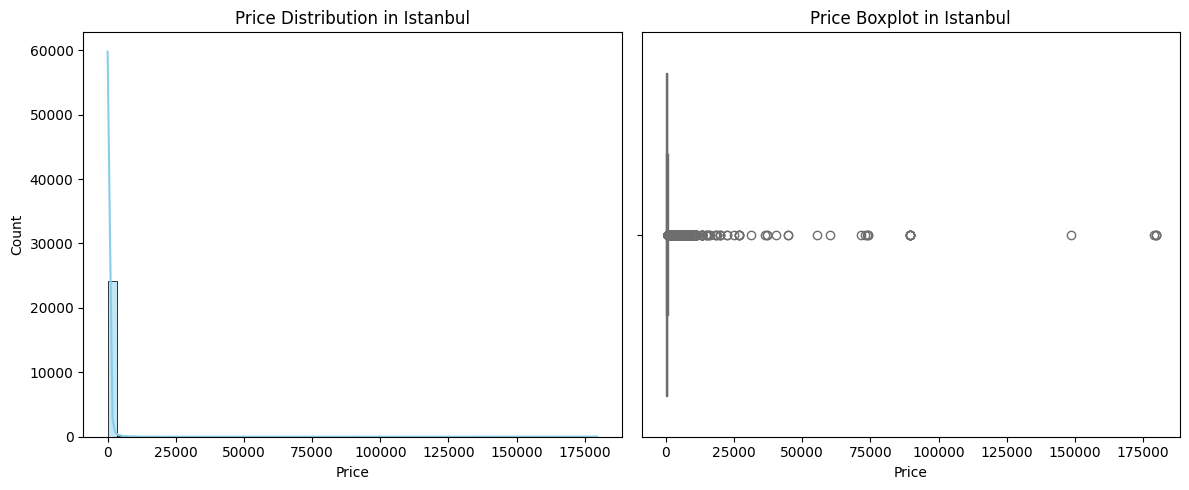



Summary statistics for Rome:


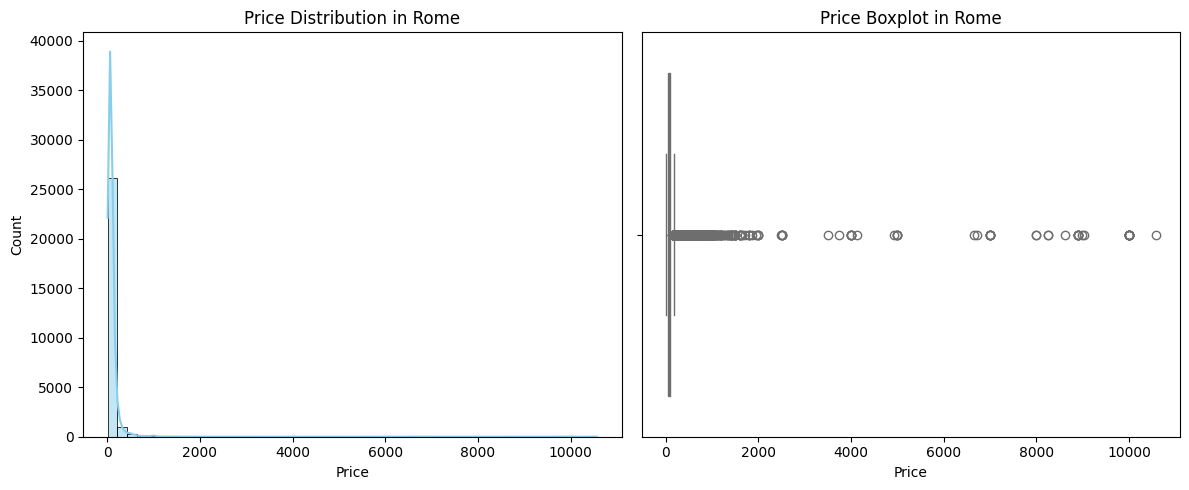



Summary statistics for Hong Kong:


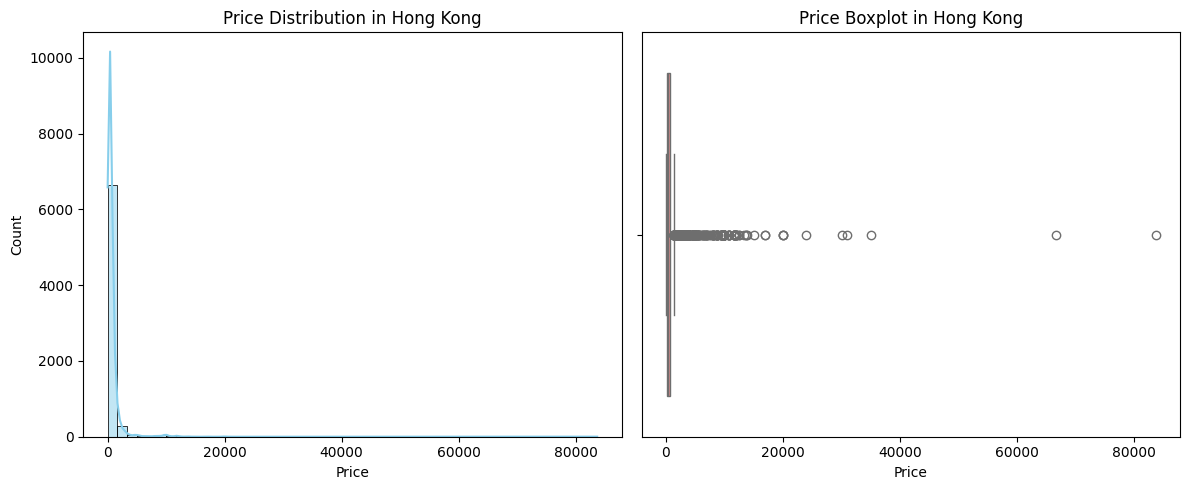



Summary statistics for Mexico City:


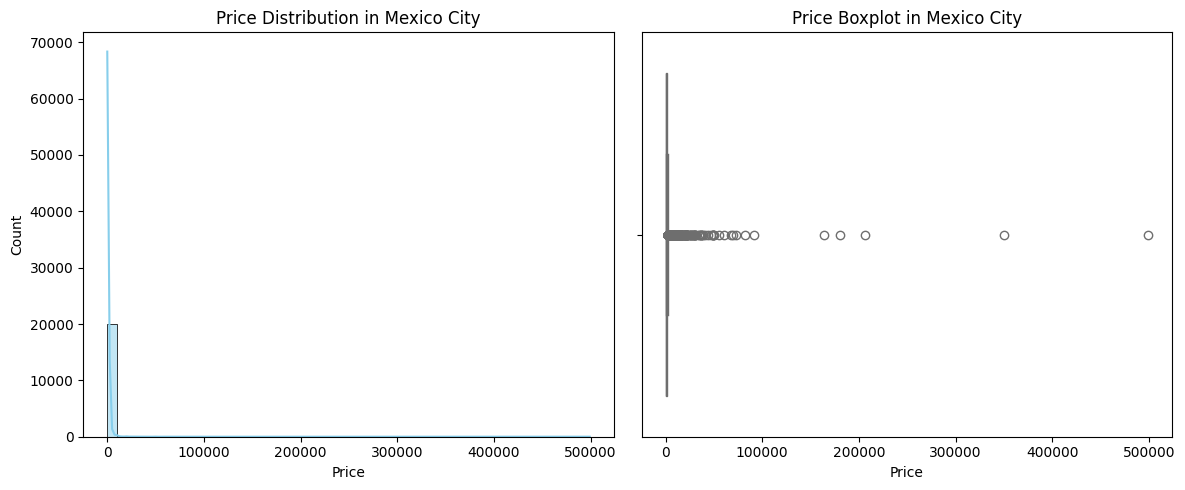



Summary statistics for Cape Town:


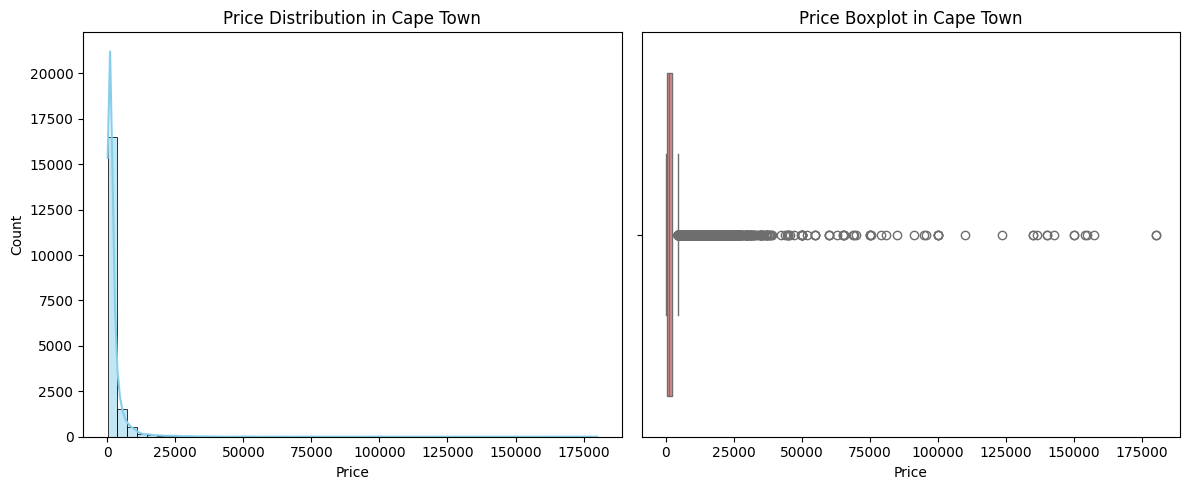

In [168]:
# check disturbution of price withing each city (make a data frame for each city , use the descriptive stats of each ,then plot it using histogram and boxplots)
cities = df_l['city'].unique()
for city in cities:
  city_df = df_l[df_l['city'] == city]
  print(f"Summary statistics for {city}:")
  plt.figure(figsize=(12, 5))
  plt.subplot(1, 2, 1)
  sns.histplot(city_df['price'], bins=50, kde=True, color='skyblue')
  plt.title(f'Price Distribution in {city}')
  plt.xlabel('Price')
  plt.ylabel('Count')
  plt.subplot(1, 2, 2)
  sns.boxplot(x=city_df['price'], color='lightcoral')
  plt.title(f'Price Boxplot in {city}')
  plt.xlabel('Price')
  plt.tight_layout()
  plt.show()
  print('\n')





### Log Transformation of Price
Since the price distributions across all cities are heavily right-skewed, applying a log transformation will help normalize the data for better statistical analysis and modeling.

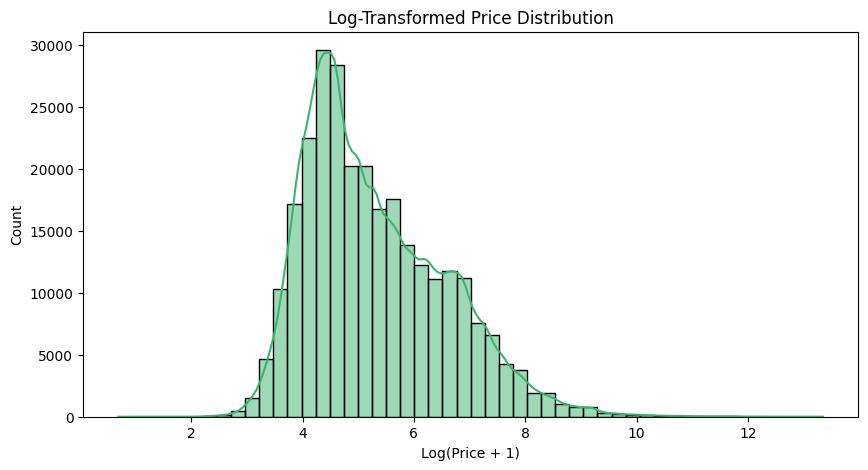

In [169]:
# Apply log transformation (using log1p to handle any potential low or 0 prices safely)
df_l['price_log'] = np.log1p(df_l['price'])

# Visualize the transformed price distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_l['price_log'], bins=50, kde=True, color='mediumseagreen')
plt.title('Log-Transformed Price Distribution')
plt.xlabel('Log(Price + 1)')
plt.ylabel('Count')
plt.show()

## Validate the Primary Key

In [176]:
df_l['listing_id'].nunique()

279599

In [177]:
df_l.shape

(279599, 35)